Benign SMB flows: 1932
Clean benign flows for training: 1932
Isolation Forest trained ✓
Benign flows flagged as anomaly (~5% expected): 97/1932 (5.0%)


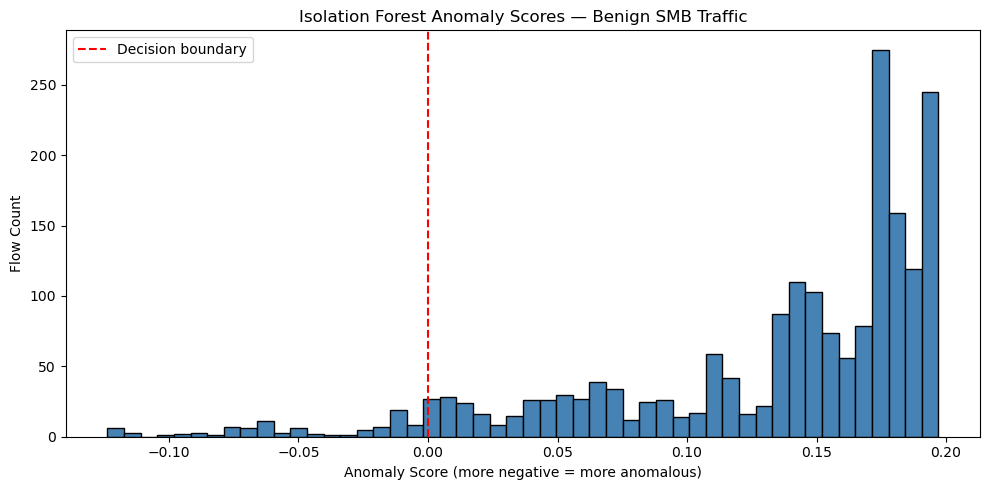

Plot saved to Desktop ✓
Model saved to Desktop ✓


In [1]:
import pandas as pd
import glob
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ── 1. Load all CSVs and extract benign port 445 flows ──
files = glob.glob('/Users/kamal/Desktop/smb dataset(5)/*.csv')
benign_frames = []

for f in files:
    df = pd.read_csv(f, low_memory=False)
    df.columns = df.columns.str.strip()
    benign_445 = df[(df['Destination Port'] == 445) & (df['Label'] == 'BENIGN')]
    benign_frames.append(benign_445)

benign_df = pd.concat(benign_frames, ignore_index=True)
print(f"Benign SMB flows: {len(benign_df)}")

# ── 2. Select flow-based features ──
features = [
    'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
    'Total Length of Fwd Packets', 'Total Length of Bwd Packets',
    'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean',
    'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean',
    'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std',
    'Fwd IAT Total', 'Bwd IAT Total', 'Fwd Packets/s', 'Bwd Packets/s',
    'Packet Length Mean', 'Packet Length Std', 'Average Packet Size',
    'Avg Fwd Segment Size', 'Avg Bwd Segment Size',
    'Init_Win_bytes_forward', 'Init_Win_bytes_backward',
    'act_data_pkt_fwd', 'min_seg_size_forward'
]

X_benign = benign_df[features].replace([np.inf, -np.inf], np.nan).dropna()
print(f"Clean benign flows for training: {len(X_benign)}")

# ── 3. Scale and train Isolation Forest ──
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_benign)

iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(X_scaled)
print("Isolation Forest trained ✓")

# ── 4. Self-check on benign data ──
preds = iso_forest.predict(X_scaled)
scores = iso_forest.decision_function(X_scaled)
flagged = (preds == -1).sum()
print(f"Benign flows flagged as anomaly (~5% expected): {flagged}/{len(X_scaled)} ({100*flagged/len(X_scaled):.1f}%)")

# ── 5. Anomaly score distribution ──
plt.figure(figsize=(10, 5))
plt.hist(scores, bins=50, color='steelblue', edgecolor='black')
plt.axvline(x=0, color='red', linestyle='--', label='Decision boundary')
plt.title('Isolation Forest Anomaly Scores — Benign SMB Traffic')
plt.xlabel('Anomaly Score (more negative = more anomalous)')
plt.ylabel('Flow Count')
plt.legend()
plt.tight_layout()
plt.savefig('/Users/kamal/Desktop/smb_anomaly_scores.png', dpi=150)
plt.show()
print("Plot saved to Desktop ✓")

# ── 6. Save model ──
import joblib
joblib.dump(iso_forest, '/Users/kamal/Desktop/smb_isolation_forest_model.pkl')
joblib.dump(scaler, '/Users/kamal/Desktop/smb_scaler.pkl')
print("Model saved to Desktop ✓")